### Distribution

A distribution describes how data values are spread.

### Observation

An observation is one individual data point/sample in a dataset.

Example:
`[2, 3, 3, 5]` → 4 observations.

### Normal / Gaussian Distribution

A symmetric, bell-shaped probability distribution.
Most values are around the mean, and fewer values are far from the mean.

**Gaussian = Normal Distribution**

### PDF — Probability Density Function

PDF describes the **density** of continuous data at different values.

A higher PDF value means the data is more concentrated around that region.

Important:
PDF value is **density**, not the probability of exactly one point.

### CDF — Cumulative Distribution Function

CDF gives the probability that a random variable is less than or equal to a value.

`CDF(x) = P(X ≤ x)`

PDF → "How dense is the data here?"

CDF → "How much probability has accumulated up to here?"

### i.i.d.

**Independent and Identically Distributed**

* Independent → observations do not depend on each other.
* Identically Distributed → observations come from the same distribution.

### Kernel

A function used to create a small smooth **bump** around each observation.

Gaussian is one possible kernel.

### KDE — Kernel Density Estimation

A non-parametric method for estimating the probability density of data.

Basic idea:

1. Put a small kernel/bump on each observation.
2. Add all bumps together.
3. The result is a smooth estimate of the data distribution.

### Bandwidth (h)

Controls the width/smoothness of the bumps.

Small `h` → narrow bumps → more detailed/spiky curve.

Large `h` → wide bumps → smoother curve.

### Non-parametric

KDE does not assume that the data follows a specific distribution such as a Normal Distribution.

It estimates the distribution directly from the data.

### KDE Formula

`f̂(x) = (1 / nh) Σ K((x - xi) / h)`

* `n` → number of observations
* `xi` → each observation
* `x` → point where we want to estimate density
* `K` → kernel function
* `h` → bandwidth

### Main idea

Data → individual bumps → sum of bumps → smooth density curve


kernel density estimation -->03
--

KDE:
A method for estimating the distribution of data using a smooth curve.

Higher curve → data is more concentrated.
    
Lower curve → data is more spread out.

In [4]:
# Normal inputs
import numpy as np
import pandas as pd
from numpy.random import randn

# Import the stats library from numpy
from scipy import stats

# These are the plotting modules adn libraries we'll use:
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns

**making KDE plot manually**

**rug plot**

it puts a tick where every value occured

Rug plot shows the location of individual observations along an axis.

In [15]:
dataset = randn(25)

(0.0, 1.0)

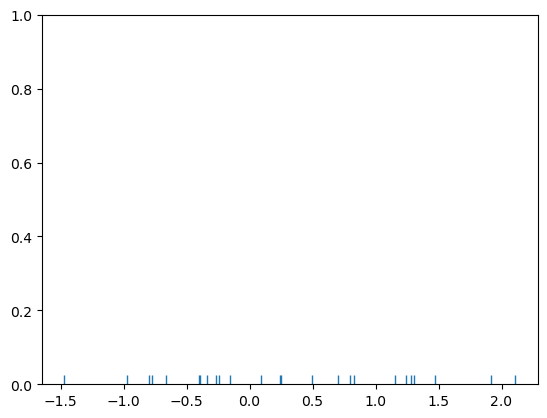

In [27]:
sns.rugplot(dataset)
plt.ylim(0,1)

**plot histograme on top of rug**

counts how many ticks is in every bin 

<Axes: >

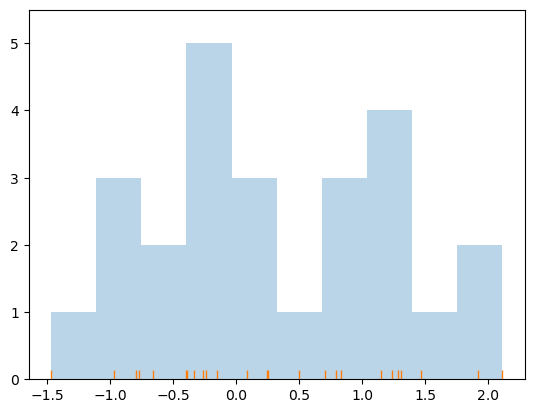

In [34]:
plt.hist(dataset,alpha=0.3)
sns.rugplot(dataset)

**KDE**

show each tick with gaussian basis func

(0.0, 1.0)

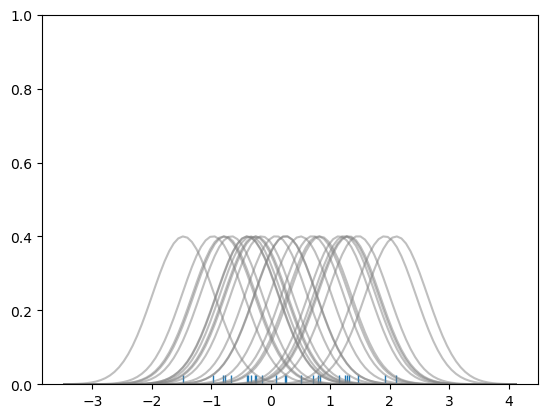

In [68]:
sns.rugplot(dataset)

x_min = dataset.min() - 2
x_max = dataset.max() + 2

# 100 equally space points
x_axis = np.linspace(x_min,x_max,100)

# A rule-of-thumb bandwidth estimator(wikipedia)
bandwidth = ((4*dataset.std()**5)/(3*len(dataset)))**0.2

kernel_list = []

for data_point in dataset:

    # create a kernel for each point and append it to the kernel_list
    # we use pdf formula . datapoint : mean , bandwidth:standard deviation
    # we calculate pdf for every data_point
    # stats.norm: making normal distribution with...
    kernel = stats.norm(data_point,bandwidth).pdf(x_axis)
    kernel_list.append(kernel)

    # Scale for plotting (better visulization)
    # ex:kernel:[0.037, 0.227, 0.285, 0.227, 0.037]
    #devide each of them to the 0.285
    kernel = kernel / kernel.max()
    kernel = kernel * 0.4

    plt.plot(x_axis,kernel,color='grey',alpha=0.5)

plt.ylim(0,1)

Text(0.5, 0.98, 'Sum of the basis functions')

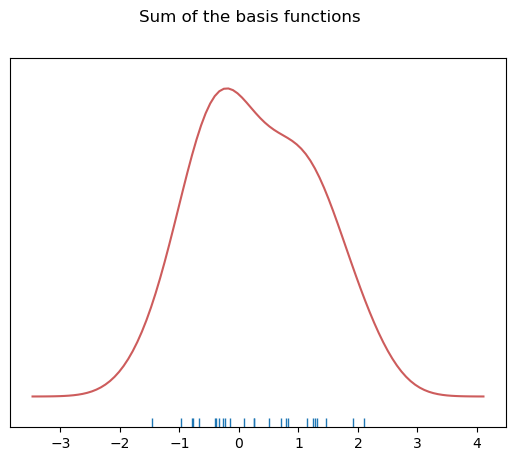

In [170]:
# axis=0 sums the kernels column by column, so values at the same x position are added together.
# ex:
# kernel_list = [
#     [1, 2, 3],
#     [4, 5, 6],
#     [7, 8, 9]
# ]
#1+4+7=12
sum_of_kde = np.sum(kernel_list,axis=0)
fig = plt.plot(x_axis,sum_of_kde,color='indianred')

sns.rugplot(dataset)

# get ride of y ticks(y axis tiks)
plt.yticks([])

plt.suptitle("Sum of the basis functions")

**seaborn**

<Axes: ylabel='Density'>

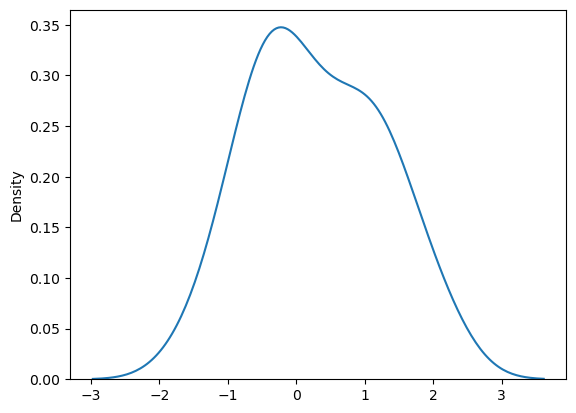

In [74]:
sns.kdeplot(dataset)

**our dataset with different bandwidths**

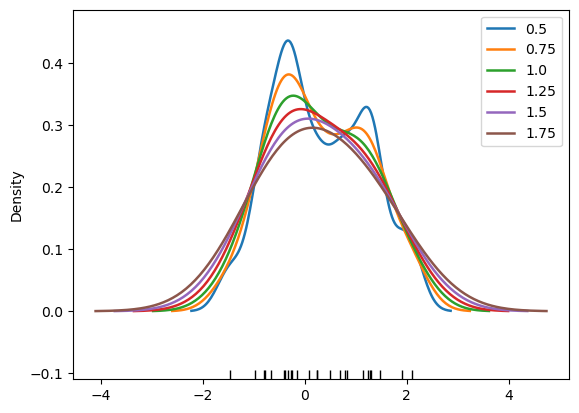

In [180]:
sns.rugplot(dataset,color='black')

for bw in np.arange(0.5,2,0.25):
    sns.kdeplot(dataset, bw_adjust=bw, lw=1.8, label=bw)
    plt.legend()

**different kernel functions**
https://en.wikipedia.org/wiki/Kernel_(statistics)

`seaborn.kdeplot()` uses a Gaussian kernel by default and handles the calculations for you

For other kernels, you need to:

* use another library 
* implement the kernel formula manually.

**plot on y axis**

<Axes: xlabel='Density'>

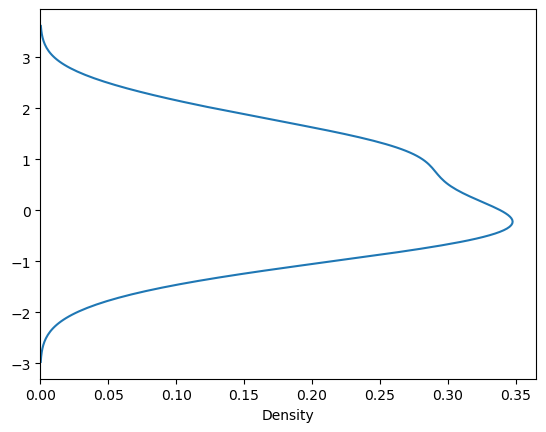

In [88]:
sns.kdeplot(y=dataset)

**kDE for cumulative distribution func(cdf)**

<Axes: ylabel='Density'>

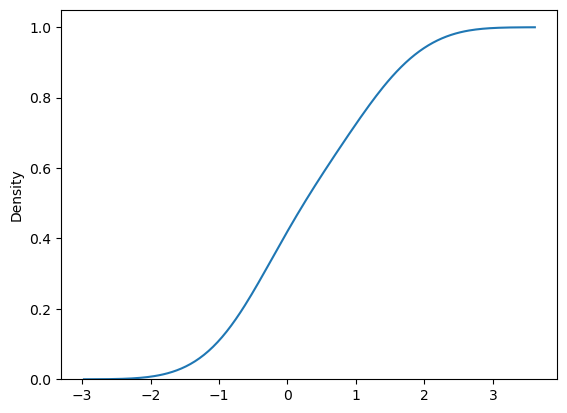

In [98]:
sns.kdeplot(dataset,cumulative=True)

**kdplot for multidimesional data(multivariate density estimation)**

**covariance matrix**
The covariance matrix shows the variance of each variable and the covariance between variables.

```python
cov = [[1, 0],
       [0, 100]]
```

* `1` → variance of X  small spread
* `100` → variance of Y large spread
* `0` → X and Y have no linear relationship


* **Variance shows spread, not the center.**
  `100` does NOT mean that Y is centered around 100.

* Since Y has variance `100`, its standard deviation is:
  `√100 = 10`

* Because the distribution is centered at `0`, Y can contain both positive and negative values.

<Axes: xlabel='X', ylabel='Y'>

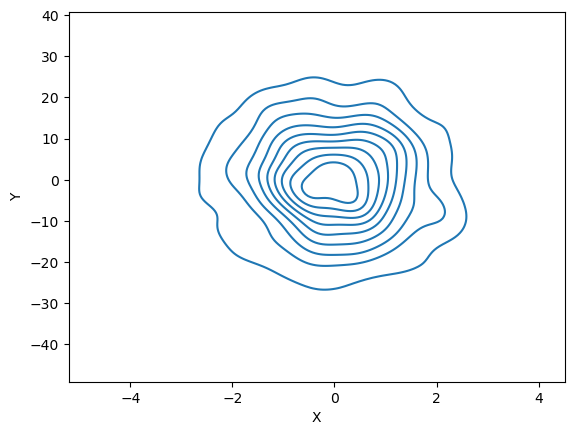

In [149]:
mean = [0,0]

cov = [[1,0],[0,100]]

dataset2 = np.random.multivariate_normal(mean,cov,1000)

dframe = pd.DataFrame(dataset2,columns=['X','Y'])

dimension_2 = sns.kdeplot(x=dframe['X'], y=dframe['Y'])
dimension_2
# sns.kdeplot(dframe)

# important Note
* **Y:** Since its variance is 100, the data has a **large spread around the mean (0)**. The values can be far from 0.

* **X:** Since its variance is 1, the data has a **small spread around the mean (0)**. The values tend to stay closer to 0.

**Important:** Variance measures how widely the data are spread around the mean, not where the data are centered.


<Axes: xlabel='X', ylabel='Y'>

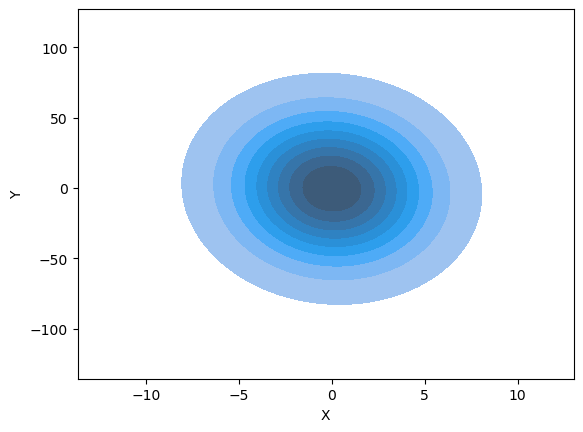

In [161]:
# Choose the bandwidth using Silverman's rule of thumb.
sns.kdeplot(x=dframe['X'], y=dframe['Y'],bw_adjust=10,fill=True)

<Axes: xlabel='X', ylabel='Y'>

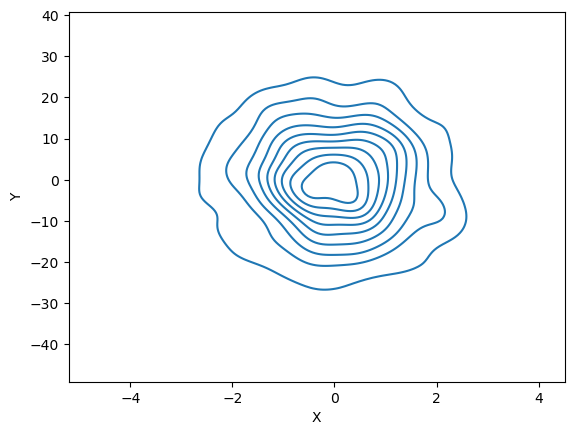

In [163]:
sns.kdeplot(x=dframe['X'], y=dframe['Y'],bw_method='silverman')

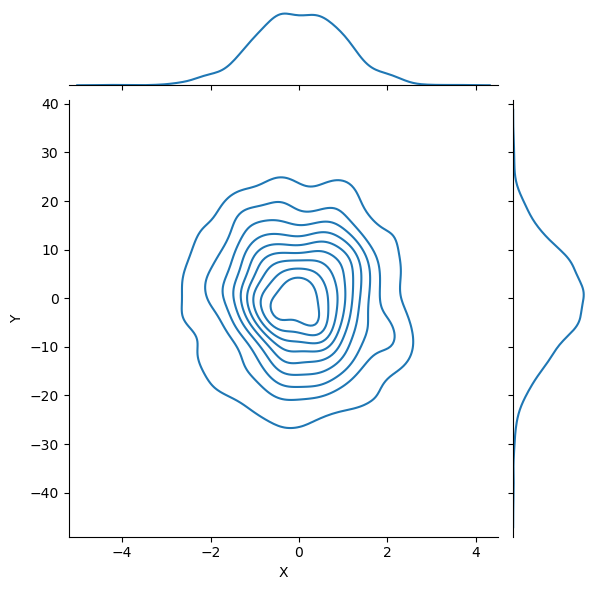

In [165]:
sns.jointplot(x=dframe['X'], y=dframe['Y'],kind='kde')